# Extended Data Fig. 2

Redraws the panels of Extended Data Fig. 2 from the source data.

The source data are deposited on figshare (https://doi.org/10.6084/m9.figshare.34601982): `Wilhelm_SourceData.xlsx` (one worksheet per panel), per-point `Wilhelm_SourceData_*.parquet` files and summary `Wilhelm_SourceData_*.csv` files; `README.md` of the deposit describes all columns. `source_data.py` downloads the files into `./data` on first use. Set `FIGSHARE_ARTICLE_ID` in the next cell (or as environment variable; `FIGSHARE_TOKEN` while the article is private), or point `SOURCE_DATA_DIR` to a local copy of the files.

* a, b: `Wilhelm_SourceData_ED_Fig2a.parquet`, `Wilhelm_SourceData_ED_Fig2b.parquet` (spectral angle of each pair of replicate spectra) with `Wilhelm_SourceData_ED_Fig2a.csv` / `Wilhelm_SourceData_ED_Fig2b.csv`
* c, d: `Wilhelm_SourceData_ED_Fig2c_d.parquet` (retention-time difference of each pair of replicate PSMs) with `Wilhelm_SourceData_ED_Fig2c.csv` / `Wilhelm_SourceData_ED_Fig2d.csv`

The parquet files are large (10^7-10^8 rows); only the needed columns are read.


In [1]:
import source_data as sd
from source_data import fetch, readme, table

# figshare article with the source data (https://doi.org/10.6084/m9.figshare.34601982); alternatively set the environment variable
# FIGSHARE_ARTICLE_ID, or SOURCE_DATA_DIR to a local copy of the files. While the article is private, set FIGSHARE_TOKEN.
sd.FIGSHARE_ARTICLE_ID = sd.FIGSHARE_ARTICLE_ID or ""

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.rcParams['pdf.fonttype'] = 42
DATA = Path('data')
DATA.mkdir(exist_ok=True)
FIG_DIR = Path('regenerated_panels') / 'ED_Fig2'
FIG_DIR.mkdir(parents=True, exist_ok=True)
COLORS = {'HCD': '#8eaadf', 'CID': '#8fd6aa'}
BOX = '#d4e8b5'


readme('ED_Fig2')

,Figure,Panel,Worksheet,figshare file(s),Content,Tables in worksheet (top to bottom)
0,Extended Data Fig. 2,a,NaN,Wilhelm_SourceData_ED_Fig2a.parquet; Wilhelm_S...,Spectral angle of each pair of replicate spect...,NaN
1,Extended Data Fig. 2,b,NaN,Wilhelm_SourceData_ED_Fig2b.parquet; Wilhelm_S...,Spectral angle of each pair of replicate spect...,NaN
2,Extended Data Fig. 2,c,NaN,Wilhelm_SourceData_ED_Fig2c_d.parquet; Wilhelm...,Retention-time difference of each pair of repl...,NaN
3,Extended Data Fig. 2,d,NaN,Wilhelm_SourceData_ED_Fig2c_d.parquet; Wilhelm...,Retention-time difference of each pair of repl...,NaN


Violins: seaborn `violinplot`, `bw_method=0.2`, default `cut=2`, `density_norm='area'`, split by fragmentation (HCD left, CID right); n = number of PSMs per QC-peptide group and fragmentation. Panel b uses all pairs; for panel a (~9 x 10^7 pairs) the densities are computed on a fixed random subsample (`random_state=0`) of at most 300,000 pairs per group and fragmentation. Box plots: median, quartiles and whiskers at the most extreme value within 1.5 x IQR, computed on all pairs, no fliers; numbers above the boxes: unique peptide-raw file combinations.

In [3]:
def violin_panel(parquet, summary_sheet, title, out_name, max_per_group=None):
    df = pd.read_parquet(parquet, columns=['label', 'fragmentation', 'spectral_angle'])
    if max_per_group:
        df = (df.groupby(['label', 'fragmentation'], observed=True, group_keys=False)
                .apply(lambda g: g.sample(min(len(g), max_per_group), random_state=0)))
    summ = table(summary_sheet)
    order = list(dict.fromkeys(summ['label']))
    fig, ax = plt.subplots(figsize=(10, 4.5))
    sns.violinplot(data=df, x='label', y='spectral_angle', hue='fragmentation', hue_order=['HCD', 'CID'],
                   split=True, inner=None, bw_method=0.2, order=order, palette=COLORS, ax=ax)
    for i, lab in enumerate(order):
        for frag, dx in [('HCD', -0.12), ('CID', 0.12)]:
            n = summ.query('label == @lab and fragmentation == @frag')['n_PSMs'].iloc[0]
            ax.text(i + dx, 0.02, f'n = {n:,}', rotation=90, ha='center', va='bottom', fontsize=7)
    ax.set_xlabel('')
    ax.set_ylabel('Spectral Angle')
    ax.set_title(title)
    ax.legend(title='', loc='center left')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.gcf().subplots_adjust(bottom=0.32)
    for ext in ('pdf', 'png'):
        plt.savefig(FIG_DIR / f'{out_name}.{ext}', dpi=300, bbox_inches='tight')
    plt.show()
    return summ


def box_panel(column, summary_sheet, title, out_name, ylim):
    df = pd.read_parquet(fetch('Wilhelm_SourceData_ED_Fig2c_d.parquet'), columns=['label', column])
    summ = table(summary_sheet)
    order = summ['label'].tolist()
    stats = []
    for lab in order:
        x = df.loc[df['label'] == lab, column].to_numpy()
        q1, med, q3 = np.percentile(x, [25, 50, 75])
        iqr = q3 - q1
        stats.append({'med': med, 'q1': q1, 'q3': q3, 'whislo': x[x >= q1 - 1.5 * iqr].min(),
                      'whishi': x[x <= q3 + 1.5 * iqr].max(), 'fliers': [], 'label': lab})
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.bxp(stats, showfliers=False, patch_artist=True, widths=0.6,
           boxprops=dict(facecolor=BOX, edgecolor='0.5'), medianprops=dict(color='0.5'),
           whiskerprops=dict(color='0.5'), capprops=dict(color='0.5'))
    for i, n in enumerate(summ['n_unique_peptide_rawfile'], start=1):
        ax.text(i, ylim[1] * 1.02, f'{n:,}', ha='center', va='bottom', fontsize=8)
    ax.set_ylim(*ylim)
    ax.set_ylabel('Delta RT (minutes)')
    ax.set_title(title, pad=18)
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.gcf().subplots_adjust(bottom=0.32)
    for ext in ('pdf', 'png'):
        plt.savefig(FIG_DIR / f'{out_name}.{ext}', dpi=300, bbox_inches='tight')
    plt.show()
    return summ

## a — spectral-angle reproducibility of QC peptides without CE calibration

Spectral angle of all pairs of replicate spectra of 79 QC peptides with identical sequence, charge, fragmentation and acquisition collision energy.

/tmp/ipykernel_1127933/649101030.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), max_per_group), random_state=0)))


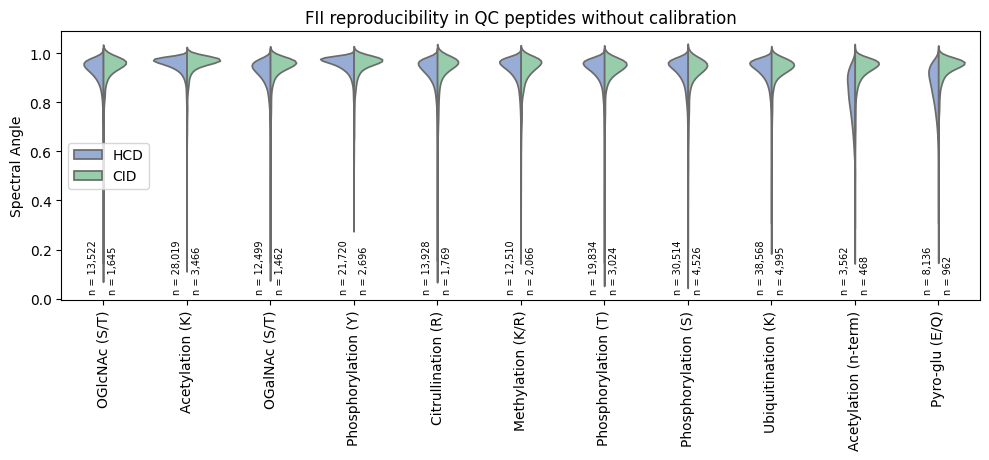

,label,package,fragmentation,n_PSMs,n_peptides,n_unique_peptide_rawfile_pairs,n_pairs,median_spectral_angle,Q1,Q3,min,max
0,OGlcNAc (S/T),TUM_mod_OGlcNAc,HCD,13522,43,564020,8745200,0.940839,0.908486,0.962632,0.161106,1
1,OGlcNAc (S/T),TUM_mod_OGlcNAc,CID,1645,44,812359,812359,0.953728,0.922964,0.970259,0.103712,1
2,Acetylation (K),TUM_mod_acetylated,HCD,28019,44,263212,4194390,0.963644,0.943869,0.976254,0.307300,1
3,Acetylation (K),TUM_mod_acetylated,CID,3466,44,358085,358085,0.968234,0.948153,0.978608,0.136533,1
4,OGalNAc (S/T),TUM_mod_OGalNAc,HCD,12499,41,481245,7470191,0.933864,0.899419,0.957075,0.163293,1
5,OGalNAc (S/T),TUM_mod_OGalNAc,CID,1462,41,675588,675588,0.954261,0.928390,0.969816,0.098625,1
6,Phosphorylation (Y),TUM_mod_pY,HCD,21720,44,59344,932868,0.965315,0.943105,0.978299,0.412511,1
7,Phosphorylation (Y),TUM_mod_pY,CID,2696,44,80646,80646,0.965070,0.934899,0.977270,0.303244,1
8,Citrullination (R),TUM_mod_citrullination,HCD,13928,41,634106,10084318,0.940894,0.907472,0.963472,0.163042,1
9,Citrullination (R),TUM_mod_citrullination,CID,1769,42,960267,960267,0.952756,0.913742,0.971332,0.098597,1


In [4]:
violin_panel(fetch('Wilhelm_SourceData_ED_Fig2a.parquet'), 'ED_Fig2a',
             'FII reproducibility in QC peptides without calibration', 'ED_Fig2a',
             max_per_group=300_000)

## b — spectral-angle reproducibility of QC peptides with CE calibration

As a (40 QC peptides), restricted to pairs whose aligned collision energies differ by < 0.1.

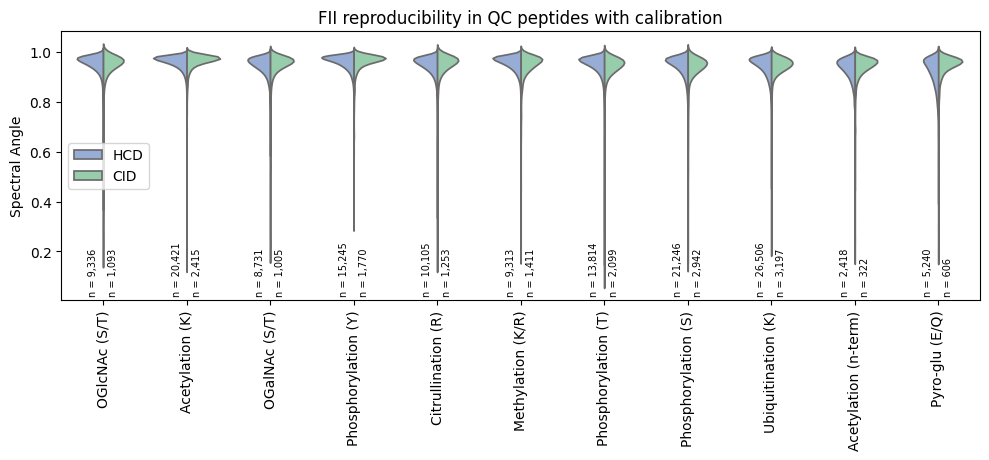

,label,package,fragmentation,n_PSMs,n_peptides,n_unique_peptide_rawfile_pairs,n_pairs,median_spectral_angle,Q1,Q3,min,max
0,OGlcNAc (S/T),TUM_mod_OGlcNAc,HCD,9336,28,28992,444700,0.963073,0.941419,0.977109,0.383598,1
1,OGlcNAc (S/T),TUM_mod_OGlcNAc,CID,1093,28,545313,545313,0.958303,0.934717,0.973597,0.169597,1
2,Acetylation (K),TUM_mod_acetylated,HCD,20421,28,27653,464454,0.967588,0.949932,0.978925,0.311174,1
3,Acetylation (K),TUM_mod_acetylated,CID,2415,28,251450,251450,0.971217,0.956134,0.980810,0.136533,1
4,OGalNAc (S/T),TUM_mod_OGalNAc,HCD,8731,28,21895,325618,0.954452,0.930305,0.971495,0.598692,1
5,OGalNAc (S/T),TUM_mod_OGalNAc,CID,1005,28,462354,462354,0.958433,0.937082,0.973094,0.178661,1
6,Phosphorylation (Y),TUM_mod_pY,HCD,15245,28,12162,162500,0.968101,0.947704,0.980022,0.594694,1
7,Phosphorylation (Y),TUM_mod_pY,CID,1770,28,53542,53542,0.970237,0.953181,0.980270,0.303244,1
8,Citrullination (R),TUM_mod_citrullination,HCD,10105,28,50569,783611,0.956780,0.933520,0.972785,0.347710,1
9,Citrullination (R),TUM_mod_citrullination,CID,1253,28,673694,673694,0.958923,0.934127,0.974680,0.147360,1


In [5]:
violin_panel(fetch('Wilhelm_SourceData_ED_Fig2b.parquet'), 'ED_Fig2b',
             'FII reproducibility in QC peptides with calibration', 'ED_Fig2b')

## c — retention-time reproducibility of QC peptides without calibration

Retention-time difference (min) of all pairs of replicate PSMs of the same QC peptide (79 QC peptides, any two raw files).

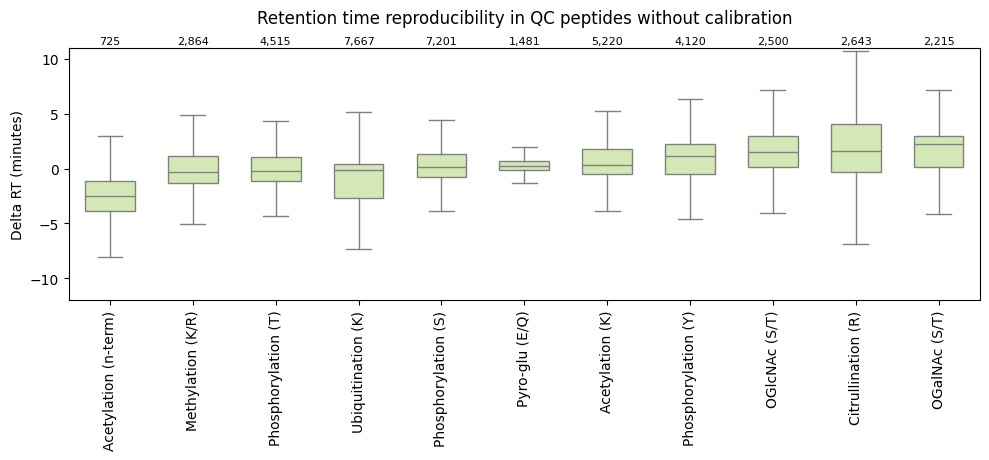

,label,package,n_unique_peptide_rawfile,n_pairs,lower_whisker_delta_RT_min,Q1_delta_RT_min,median_delta_RT_min,Q3_delta_RT_min,upper_whisker_delta_RT_min
0,Acetylation (n-term),TUM_nterm_ac,725,580987,-8.045,-3.906,-2.458,-1.146,2.993
1,Methylation (K/R),TUM_mod_monomethyl,2864,1817477,-5.055,-1.308,-0.309,1.190,4.937
2,Phosphorylation (T),TUM_mod_pT,4515,4039295,-4.365,-1.094,-0.213,1.087,4.358
3,Ubiquitination (K),TUM_mod_ubi,7667,1430665,-7.355,-2.659,-0.146,0.472,5.168
4,Phosphorylation (S),TUM_mod_pS,7201,7216547,-3.819,-0.728,0.136,1.333,4.424
5,Pyro-glu (E/Q),TUM_mod_pyroGlu,1481,24448,-1.351,-0.119,0.209,0.703,1.935
6,Acetylation (K),TUM_mod_acetylated,5220,3933875,-3.871,-0.452,0.360,1.828,5.247
7,Phosphorylation (Y),TUM_mod_pY,4120,1530835,-4.604,-0.477,1.169,2.275,6.402
8,OGlcNAc (S/T),TUM_mod_OGlcNAc,2500,1136324,-4.083,0.142,1.510,2.959,7.184
9,Citrullination (R),TUM_mod_citrullination,2643,176265,-6.886,-0.304,1.594,4.096,10.696


In [6]:
box_panel('delta_RT_min', 'ED_Fig2c', 'Retention time reproducibility in QC peptides without calibration',
          'ED_Fig2c', (-12, 11))

## d — retention-time reproducibility of QC peptides with iRT calibration

Difference in iRT of the same pairs after linear rescaling of iRT to the minute range of the data (min).

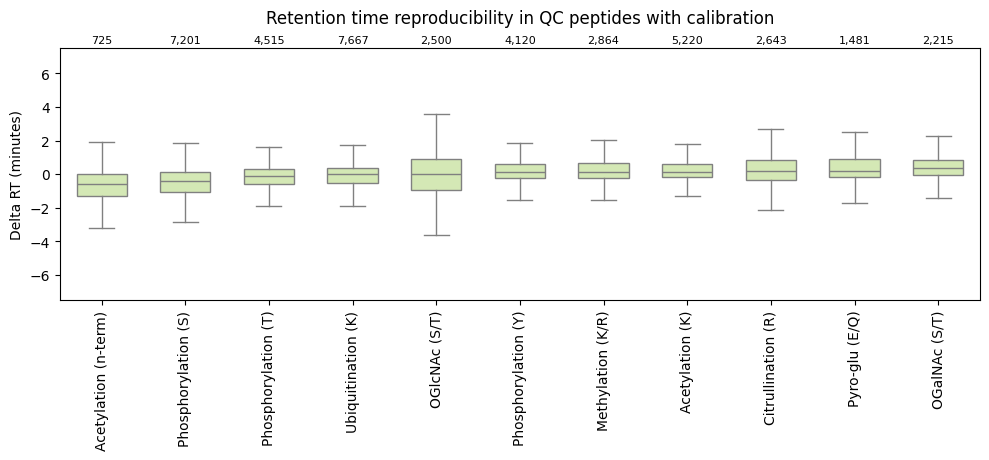

,label,package,n_unique_peptide_rawfile,n_pairs,lower_whisker_delta_iRT_rescaled_min,Q1_delta_iRT_rescaled_min,median_delta_iRT_rescaled_min,Q3_delta_iRT_rescaled_min,upper_whisker_delta_iRT_rescaled_min
0,Acetylation (n-term),TUM_nterm_ac,725,580987,-3.187664,-1.275111,-0.613814,0.000000,1.912557
1,Phosphorylation (S),TUM_mod_pS,7201,7216547,-2.862605,-1.083569,-0.401285,0.102455,1.881490
2,Phosphorylation (T),TUM_mod_pT,4515,4039295,-1.883859,-0.576231,-0.088531,0.295523,1.603153
3,Ubiquitination (K),TUM_mod_ubi,7667,1430665,-1.871092,-0.521954,-0.007674,0.377477,1.726606
4,OGlcNAc (S/T),TUM_mod_OGlcNAc,2500,1136324,-3.628858,-0.921661,0.000000,0.883148,3.590315
5,Phosphorylation (Y),TUM_mod_pY,4120,1530835,-1.528010,-0.253368,0.104850,0.596424,1.871087
6,Methylation (K/R),TUM_mod_monomethyl,2864,1817477,-1.565653,-0.224189,0.122818,0.670123,2.011567
7,Acetylation (K),TUM_mod_acetylated,5220,3933875,-1.310123,-0.150518,0.144071,0.622560,1.782178
8,Citrullination (R),TUM_mod_citrullination,2643,176265,-2.141464,-0.338304,0.173129,0.863886,2.667024
9,Pyro-glu (E/Q),TUM_mod_pyroGlu,1481,24448,-1.722916,-0.145003,0.204596,0.908676,2.486773


In [7]:
box_panel('delta_iRT_rescaled_min', 'ED_Fig2d', 'Retention time reproducibility in QC peptides with calibration',
          'ED_Fig2d', (-7.5, 7.5))